# Lab 12 Transformers Complete Solution

In [1]:
import os
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
from pathlib import Path

os.environ['USE_TF'] = '0'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForPreTraining

torch.manual_seed(42)
torch.set_num_threads(2)
cache_dir = Path.cwd() / 'lab12_model_cache'
cache_dir.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__)

def checkpoint(repository, folder):
    import requests
    repository = {'bert-base-uncased': 'google-bert/bert-base-uncased', 'distilbert-base-uncased-finetuned-sst-2-english': 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'}.get(repository, repository)
    destination = cache_dir / 'local_checkpoints' / (folder + '_verified')
    destination.mkdir(parents=True, exist_ok=True)
    for filename in ['config.json', 'tokenizer_config.json', 'vocab.txt', 'model.safetensors']:
        target = destination / filename
        if not target.exists():
            temporary = target.with_suffix(target.suffix + '.part')
            url = f'https://huggingface.co/{repository}/resolve/main/{filename}?download=true'
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                with temporary.open('wb') as stream:
                    for chunk in response.iter_content(1024 * 1024):
                        stream.write(chunk)
            temporary.replace(target)
    return destination


PyTorch: 2.9.0+cpu
Transformers: 4.57.6


## 1 Load the sentiment Transformer

In [2]:
model_name = 'distilbert-base-uncased-finetuned-sst-2-english'
distilbert_path = checkpoint(model_name, 'distilbert')
tokenizer = AutoTokenizer.from_pretrained(distilbert_path, cache_dir=cache_dir)
model = AutoModelForSequenceClassification.from_pretrained(distilbert_path, cache_dir=cache_dir, attn_implementation='eager')
model.eval()
print('Transformer layers:', model.config.n_layers)
print('Attention heads per layer:', model.config.n_heads)
print('Hidden size:', model.config.dim)

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768


## 2 Tokenize the supplied sentence

In [3]:
sentence = 'The movie was not good.'
inputs = tokenizer(sentence, return_tensors='pt')
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
print('Sentence:', sentence)
print('Tokens:', tokens)
print('Token IDs:', inputs['input_ids'][0].tolist())

Sentence: The movie was not good.
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Token IDs: [101, 1996, 3185, 2001, 2025, 2204, 1012, 102]


## 3 Embeddings and self attention

Embeddings shape: (1, 8, 768)
Attention shape: (8, 8)
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


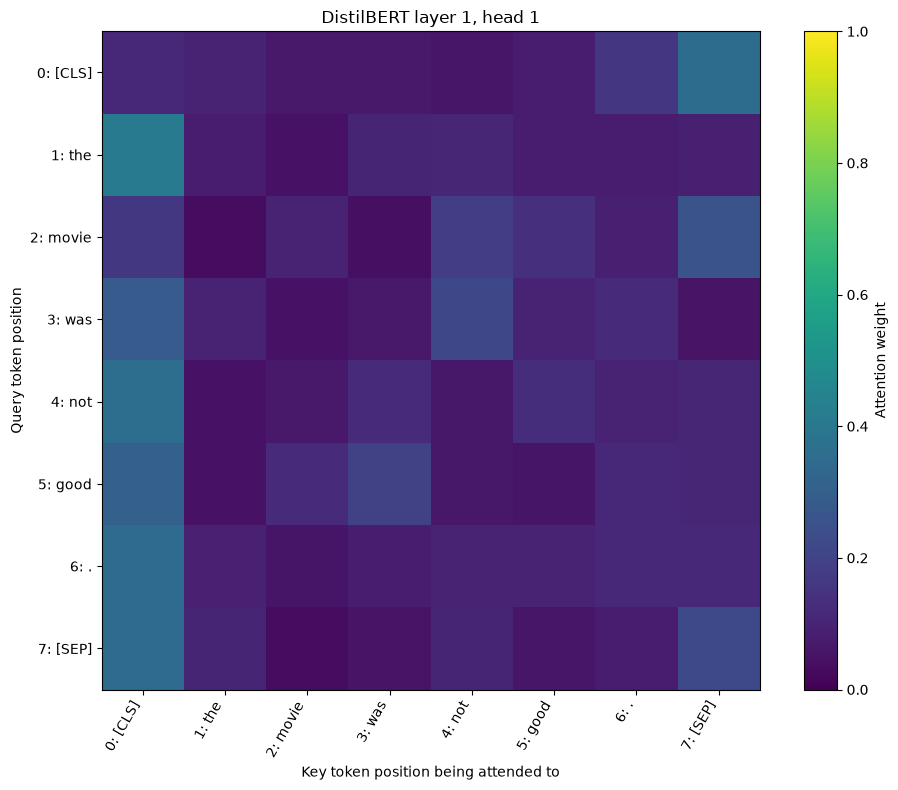

In [4]:
with torch.inference_mode():
    embeddings = model.distilbert.embeddings(inputs['input_ids'])
    outputs = model(**inputs, output_attentions=True)
attention = outputs.attentions[0][0, 0]
print('Embeddings shape:', tuple(embeddings.shape))
print('Attention shape:', tuple(attention.shape))
print('Tokens:', tokens)
print('Attention weights:')
print(attention)

def plot_attention(matrix, labels, title):
    fig, ax = plt.subplots(figsize=(10, 8))
    plot = ax.imshow(matrix.cpu().numpy(), cmap='viridis', vmin=0, vmax=1)
    positions = list(range(len(labels)))
    ax.set_xticks(positions, [f'{i}: {token}' for i, token in enumerate(labels)], rotation=60, ha='right')
    ax.set_yticks(positions, [f'{i}: {token}' for i, token in enumerate(labels)])
    ax.set_xlabel('Key token position being attended to')
    ax.set_ylabel('Query token position')
    ax.set_title(title)
    fig.colorbar(plot, ax=ax, label='Attention weight')
    fig.tight_layout()
    plt.show()

plot_attention(attention, tokens, 'DistilBERT layer 1, head 1')

## 4 Sentiment classification

In [5]:
logits = outputs.logits
probs = torch.softmax(logits, dim=1)[0]
prediction = int(probs.argmax())
for index, probability in enumerate(probs):
    print(f'{model.config.id2label[index]}: {probability.item():.6f}')
print('Prediction:', model.config.id2label[prediction])
print('Confidence:', round(probs[prediction].item(), 3))

NEGATIVE: 0.999773
POSITIVE: 0.000227
Prediction: NEGATIVE
Confidence: 1.0


## Task Parts 1 and 2 BERT layers and total attention heads

In [6]:
bert_name = 'bert-base-uncased'
bert_path = checkpoint(bert_name, 'bert')
bert_tokenizer = AutoTokenizer.from_pretrained(bert_path, cache_dir=cache_dir)
bert_model = AutoModelForPreTraining.from_pretrained(bert_path, cache_dir=cache_dir, attn_implementation='eager')
bert_model.eval()
layer_count = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads
total_heads = layer_count * heads_per_layer
print('BERT checkpoint:', bert_name)
print('Number of Transformer layers:', layer_count)
print('Attention heads per layer:', heads_per_layer)
print(f'Total attention heads: {layer_count} x {heads_per_layer} = {total_heads}')

BERT checkpoint: bert-base-uncased
Number of Transformer layers: 12
Attention heads per layer: 12
Total attention heads: 12 x 12 = 144


## Task Part 3 Extract the third layer and second head

Sentence: Transformers use self-attention to understand language.
Indexed tokens: [(0, '[CLS]'), (1, 'transformers'), (2, 'use'), (3, 'self'), (4, '-'), (5, 'attention'), (6, 'to'), (7, 'understand'), (8, 'language'), (9, '.'), (10, '[SEP]')]
All layer tensors: 12
Selected layer tensor shape: (1, 12, 11, 11)
Third layer, second head matrix shape: (11, 11)
Attention matrix:
tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01,

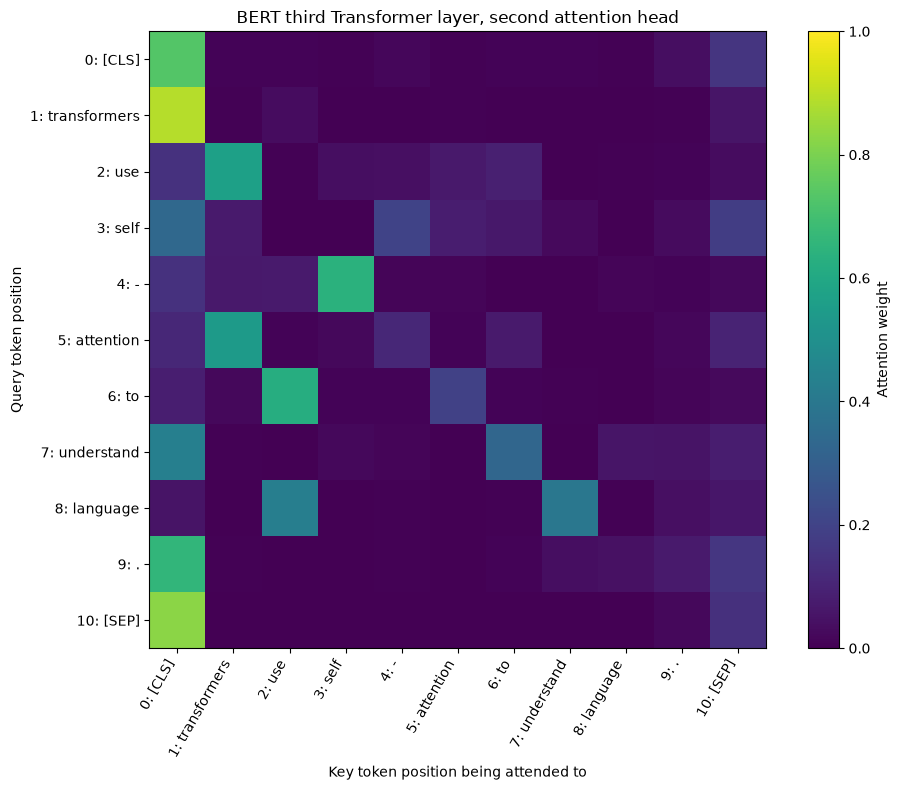

In [7]:
task_sentence = 'Transformers use self-attention to understand language.'
bert_inputs = bert_tokenizer(task_sentence, return_tensors='pt')
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs['input_ids'][0])
with torch.inference_mode():
    bert_outputs = bert_model.bert(**bert_inputs, output_attentions=True, return_dict=True)
layer_index = 2
head_index = 1
task_attention = bert_outputs.attentions[layer_index][0, head_index]
print('Sentence:', task_sentence)
print('Indexed tokens:', list(enumerate(bert_tokens)))
print('All layer tensors:', len(bert_outputs.attentions))
print('Selected layer tensor shape:', tuple(bert_outputs.attentions[layer_index].shape))
print('Third layer, second head matrix shape:', tuple(task_attention.shape))
print('Attention matrix:')
print(task_attention)
plot_attention(task_attention, bert_tokens, 'BERT third Transformer layer, second attention head')

## Task Part 4 What rows and columns represent

## Verification

In [8]:
assert layer_count == 12 and heads_per_layer == 12 and total_heads == 144
assert len(bert_outputs.attentions) == layer_count
assert bert_outputs.attentions[2].shape[1] == heads_per_layer
assert task_attention.shape == (len(bert_tokens), len(bert_tokens))
assert torch.equal(task_attention, bert_outputs.attentions[2][0, 1])
assert embeddings.shape == (1, len(tokens), model.config.dim)
assert torch.isfinite(logits).all() and torch.isfinite(task_attention).all()
assert torch.allclose(probs.sum(), torch.tensor(1.0), atol=1e-6)
for matrix in [attention, task_attention]:
    assert torch.all(matrix >= 0) and torch.all(matrix <= 1)
    assert torch.allclose(matrix.sum(dim=-1), torch.ones(matrix.shape[0]), atol=1e-5)
print('All architecture, indexing, probability and attention checks passed.')

All architecture, indexing, probability and attention checks passed.
